# 03 · Zero-shot + linear probes


## 0 · Setup

In [2]:
!pip install -q open_clip_torch

from google.colab import drive
drive.mount('/content/drive')

import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJECT = Path('/content/drive/MyDrive/345_term_project')
DATA, FEATS, RESULTS = PROJECT / 'data', PROJECT / 'features', PROJECT / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## 1 · Load splits + features

In [3]:
splits = pd.read_csv(DATA / 'splits.csv')
assert json.loads((FEATS / 'image_ids.json').read_text()) == splits['image_id'].tolist(), 'feature rows out of order'

FEATURES = {
    'BiomedCLIP': np.load(FEATS / 'biomedclip_image.npy'),
    'DINOv3':     np.hstack([np.load(FEATS / 'dinov3_cls.npy'), np.load(FEATS / 'dinov3_patchmean.npy')]),
}
y = splits['label'].to_numpy()
TRAIN = np.flatnonzero(splits['split'] == 'train')
VAL   = np.flatnonzero(splits['split'] == 'val')
TEST  = np.flatnonzero(splits['split'] == 'test')

for k, X in FEATURES.items():
    print(f'{k:10s} {X.shape}')
print(f'train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)} | test pneumonia rate (PR-AUC chance) {y[TEST].mean():.3f}')

BiomedCLIP (26684, 512)
DINOv3     (26684, 1536)
train 18881 | val 3966 | test 3837 | test pneumonia rate (PR-AUC chance) 0.224


## 2 · Metrics

In [4]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, confusion_matrix)

def val_threshold(y_val, p_val):
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.argmax(f1[:-1])]

def evaluate(p_val, p_test):
    t = val_threshold(y[VAL], p_val)
    yt, pred = y[TEST], (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return {
        'val_pr_auc':  average_precision_score(y[VAL], p_val),
        'pr_auc':      average_precision_score(yt, p_test),
        'auroc':       roc_auc_score(yt, p_test),
        'f1':          f1_score(yt, pred, zero_division=0),
        'sensitivity': tp / (tp + fn),
        'specificity': tn / (tn + fp),
        'accuracy':    (tp + tn) / len(yt),
        'threshold':   t,
    }

## 3 · Zero-shot BiomedCLIP
Score = softmax over (pneumonia prompt, normal prompt). Best prompt chosen on val.

In [5]:
import torch
from open_clip import create_model_from_pretrained, get_tokenizer

BMC_NAME = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
bmc, _ = create_model_from_pretrained(BMC_NAME)
tokenizer = get_tokenizer(BMC_NAME)
bmc.eval()

PROMPTS = {
    'plain':      ('a chest X-ray showing pneumonia', 'a normal chest X-ray'),
    'radiology':  ('chest radiograph with lung opacity consistent with pneumonia', 'chest radiograph with clear lungs'),
    'biomedclip': ('this is a photo of pneumonia', 'this is a photo of a normal chest X-ray'),
    'findings':   ('chest X-ray with pneumonia', 'chest X-ray with no findings'),
}

img = torch.tensor(FEATURES['BiomedCLIP'])
img = img / img.norm(dim=-1, keepdim=True)

zs_rows, zs_scores = [], {}
with torch.no_grad():
    for name, pair in PROMPTS.items():
        txt = bmc.encode_text(tokenizer(list(pair), context_length=256))
        txt = txt / txt.norm(dim=-1, keepdim=True)
        p = (bmc.logit_scale.exp() * img @ txt.T).softmax(-1)[:, 0].numpy()
        zs_scores[name] = p
        zs_rows.append({'prompt': name, 'pneumonia_text': pair[0], 'normal_text': pair[1], **evaluate(p[VAL], p[TEST])})

zeroshot = pd.DataFrame(zs_rows).sort_values('val_pr_auc', ascending=False)
BEST_PROMPT = zeroshot.iloc[0]['prompt']
zeroshot.to_csv(RESULTS / 'zeroshot.csv', index=False)
print('best prompt on val:', BEST_PROMPT)
zeroshot.drop(columns=['pneumonia_text', 'normal_text']).round(3)

open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

best prompt on val: biomedclip


,prompt,val_pr_auc,pr_auc,auroc,f1,sensitivity,specificity,accuracy,threshold
2,biomedclip,0.532,0.602,0.837,0.587,0.633,0.848,0.800,0.014
0,plain,0.528,0.585,0.840,0.583,0.778,0.743,0.751,0.903
3,findings,0.528,0.575,0.831,0.571,0.676,0.800,0.772,0.790
1,radiology,0.456,0.508,0.811,0.559,0.750,0.731,0.735,0.705


## 4 · Linear probe (PyTorch)
One `nn.Linear` on standardized frozen features, cross-entropy, Adam, batch 256.

In [6]:
import torch.nn as nn

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
LR_GRID    = [3e-4, 1e-3, 3e-3, 1e-2]
WD_GRID    = [0, 1e-3, 1e-2]
BATCH      = 256
MAX_EPOCHS = 200
PATIENCE   = 20
SEED       = 0

def standardize(X):
    Xt = torch.tensor(X, dtype=torch.float32, device=DEVICE)
    mu, sd = Xt[TRAIN].mean(0), Xt[TRAIN].std(0) + 1e-6
    return (Xt - mu) / sd, mu, sd

def train_head(Z, lr, wd):
    """Returns (best head, best val PR-AUC, best epoch)."""
    torch.manual_seed(SEED)
    gen = torch.Generator().manual_seed(SEED)
    Ztr = Z[TRAIN]
    ytr = torch.tensor(y[TRAIN], dtype=torch.float32, device=DEVICE)
    head = nn.Linear(Z.shape[1], 1).to(DEVICE)
    opt = torch.optim.Adam(head.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss()

    best_score, best_state, best_epoch, waited = -1.0, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        perm = torch.randperm(len(Ztr), generator=gen).to(DEVICE)
        for start in range(0, len(Ztr), BATCH):
            idx = perm[start:start + BATCH]
            loss = loss_fn(head(Ztr[idx]).squeeze(1), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            val_score = average_precision_score(y[VAL], torch.sigmoid(head(Z[VAL]).squeeze(1)).cpu().numpy())
        if val_score > best_score + 1e-4:
            best_score, best_epoch, waited = val_score, epoch, 0
            best_state = {k: v.clone() for k, v in head.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                break
    head.load_state_dict(best_state)
    return head, best_score, best_epoch

### Sweep: LR × weight decay (12 configs per backbone)

In [7]:
sweep_rows, probe_rows, probe_scores = [], [], {}
for backbone, X in FEATURES.items():
    Z, mu, sd = standardize(X)
    best = None
    for lr in LR_GRID:
        for wd in WD_GRID:
            head, score, epoch = train_head(Z, lr, wd)
            sweep_rows.append({'backbone': backbone, 'lr': lr, 'weight_decay': wd, 'best_epoch': epoch, 'val_pr_auc': score})
            if best is None or score > best['score']:
                best = {'score': score, 'lr': lr, 'weight_decay': wd, 'epochs': epoch, 'head': head}
    with torch.no_grad():
        p = torch.sigmoid(best['head'](Z).squeeze(1)).cpu().numpy()
        W = best['head'].weight / sd
        b = best['head'].bias - (W * mu).sum()
    torch.save({'weight': W.cpu(), 'bias': b.cpu()}, RESULTS / f'probe_head_{backbone}.pt')
    probe_scores[backbone] = p
    probe_rows.append({'backbone': backbone, 'lr': best['lr'], 'weight_decay': best['weight_decay'],
                       'epochs': best['epochs'], **evaluate(p[VAL], p[TEST])})
    print(f"{backbone}: best lr={best['lr']:g}, wd={best['weight_decay']:g}, epoch {best['epochs']}, val PR-AUC {best['score']:.3f}")

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RESULTS / 'probe_sweep.csv', index=False)
probes = pd.DataFrame(probe_rows)
probes.to_csv(RESULTS / 'linear_probes.csv', index=False)

from IPython.display import display
for backbone in FEATURES:
    print(f'\n{backbone} sweep (val PR-AUC)')
    display(sweep[sweep.backbone == backbone].drop(columns='backbone').reset_index(drop=True).round({'val_pr_auc': 3}))

BiomedCLIP: best lr=0.001, wd=0.01, epoch 14, val PR-AUC 0.629
DINOv3: best lr=0.001, wd=0.01, epoch 26, val PR-AUC 0.626

BiomedCLIP sweep (val PR-AUC)


,lr,weight_decay,best_epoch,val_pr_auc
0,0.0003,0.000,26,0.628
1,0.0003,0.001,26,0.628
2,0.0003,0.010,26,0.629
3,0.0010,0.000,14,0.628
4,0.0010,0.001,14,0.628
5,0.0010,0.010,14,0.629
6,0.0030,0.000,16,0.627
7,0.0030,0.001,16,0.628
8,0.0030,0.010,16,0.628
9,0.0100,0.000,21,0.624



DINOv3 sweep (val PR-AUC)


,lr,weight_decay,best_epoch,val_pr_auc
0,0.0003,0.000,28,0.622
1,0.0003,0.001,28,0.622
2,0.0003,0.010,52,0.623
3,0.0010,0.000,26,0.624
4,0.0010,0.001,26,0.624
5,0.0010,0.010,26,0.626
6,0.0030,0.000,8,0.617
7,0.0030,0.001,8,0.617
8,0.0030,0.010,8,0.618
9,0.0100,0.000,13,0.594


## 5 · Results (test set)

In [8]:
METRICS = ['pr_auc', 'auroc', 'f1', 'sensitivity', 'specificity', 'accuracy']
results = pd.concat([
    zeroshot.iloc[[0]].assign(method=f'BiomedCLIP zero-shot ({BEST_PROMPT})'),
    probes.assign(method=probes['backbone'] + ' linear probe'),
]).set_index('method')[METRICS]
results.to_csv(RESULTS / 'results_summary.csv')
print(f'PR-AUC chance level = {y[TEST].mean():.3f}')
results.round(3)

PR-AUC chance level = 0.224


,pr_auc,auroc,f1,sensitivity,specificity,accuracy
method,,,,,,
BiomedCLIP zero-shot (biomedclip),0.602,0.837,0.587,0.633,0.848,0.800
BiomedCLIP linear probe,0.659,0.853,0.610,0.674,0.846,0.807
DINOv3 linear probe,0.637,0.838,0.591,0.651,0.841,0.799


## 6 · PR curves + confusion matrices (test)

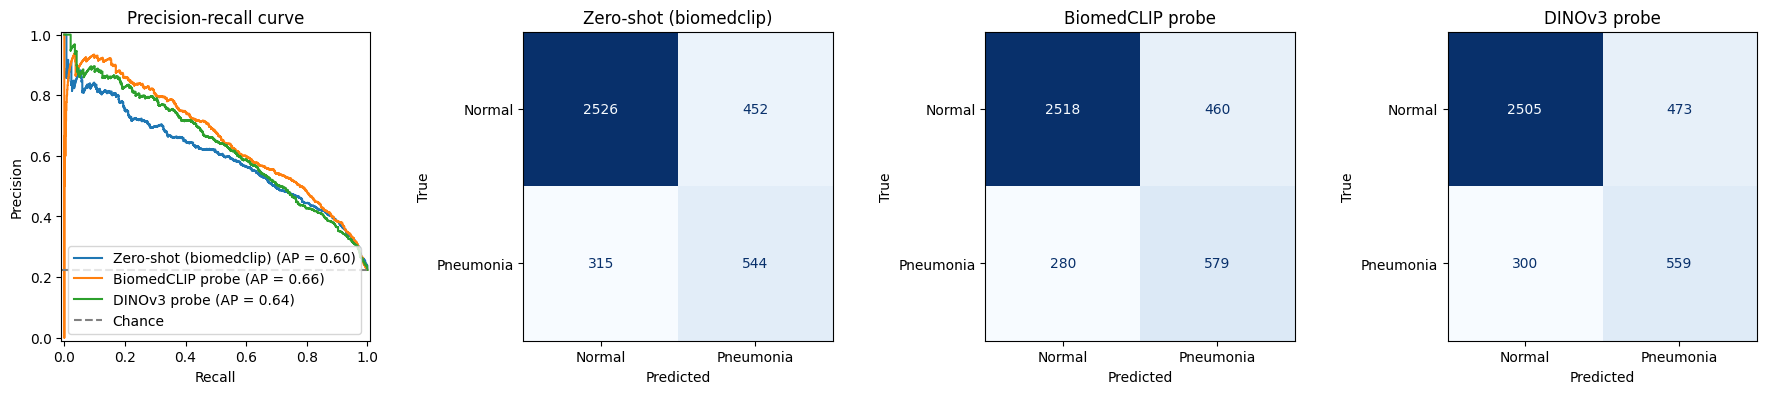

In [9]:
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay

final = {
    f'Zero-shot ({BEST_PROMPT})': (zs_scores[BEST_PROMPT], zeroshot.iloc[0]['threshold']),
    **{f'{r.backbone} probe': (probe_scores[r.backbone], r.threshold) for r in probes.itertuples()},
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for name, (p, t) in final.items():
    PrecisionRecallDisplay.from_predictions(y[TEST], p[TEST], name=name, ax=axes[0])
axes[0].axhline(y[TEST].mean(), color='gray', ls='--', label='Chance')
axes[0].set(title='Precision-recall curve', xlabel='Recall', ylabel='Precision')
axes[0].legend()

for ax, (name, (p, t)) in zip(axes[1:], final.items()):
    ConfusionMatrixDisplay.from_predictions(y[TEST], (p[TEST] >= t).astype(int), display_labels=['Normal', 'Pneumonia'],
                                            ax=ax, colorbar=False, cmap='Blues')
    ax.set(title=name, xlabel='Predicted', ylabel='True')
plt.tight_layout(); plt.savefig(RESULTS / 'pr_curves_confusion.png', dpi=150)